In [18]:
#imports
# Standard libraries
import math                                                 # Mathematical functions (sin, cos, sqrt, etc.)
import random                                               # Random number generation and sampling
import sys                                                  # System-specific parameters and functions (e.g. exit, argv)
import os                                                   # Operating system interfaces (file paths, environment variables)

# Scientific computing and data handling
import numpy as np                                          # Numerical computing (arrays, linear algebra, etc.)
import matplotlib.pyplot as plt                             # Plotting and visualization
import csv                                                  # Reading and writing CSV files
import pandas as pd                                         # Data manipulation and analysis (DataFrames, Series)
import scipy.io

# Python type hints and data structures
from dataclasses import dataclass                           # Decorator for creating classes with auto-generated special methods
from typing import Tuple                                    # Type hints for tuples and other complex types

# PyTorch: Deep learning framework
import torch                                                # Tensors and neural network building blocks
from torch import nn                                        # Neural network layers and loss functions
from torch.utils.data import Dataset, DataLoader            # Dataset and batch loading utilities

# PyTorch Lightning: High-level interface for PyTorch
import lightning as L                                       # Core Lightning module
from lightning.pytorch import Trainer                       # Training loop management
from lightning.pytorch.callbacks import (                   # Training utilities:
    EarlyStopping,                                          # Stop training when a metric stops improving
    ModelCheckpoint,                                        # Save the best model during training
    TQDMProgressBar                                         # Progress bar for training
)
from lightning.pytorch.loggers import TensorBoardLogger     # Logging to TensorBoard

# Metrics for model evaluation
import torchmetrics as tm                                   # Collection of metrics (RMSE, Accuracy, etc.) for PyTorch


device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print(device)

Te = 0.05

cuda


In [34]:
def load_csv_to_tensors(input_csv: str, target_csv: str, input_size: int = 1, output_size: int = 1, has_header: bool = False):
    """
    Load two CSV files (inputs U and outputs Y) and convert them into PyTorch tensors.
    
    Assumptions:
      - Each row in the CSV represents a full sequence (trajectory)
      - Columns represent time steps in a 'wide' format
      - input_size and output_size define the number of features per time step
    
    Args:
        input_csv (str): Path to the CSV file containing input sequences (U)
        target_csv (str): Path to the CSV file containing output sequences (Y)
        input_size (int): Number of input features per time step
        output_size (int): Number of output features per time step
        has_header (bool): True if the CSV files include a header row
    
    Returns:
        X (torch.Tensor): Input tensor of shape (N, T, input_size)
        Y (torch.Tensor): Output tensor of shape (N, T, output_size)
    """
    
    # Determine header option for pandas
    header = 0 if has_header else None
    
    # Load CSV files into NumPy arrays (float32 for PyTorch compatibility)
    U = pd.read_csv(input_csv, header=header).values.astype('float32')
    Y = pd.read_csv(target_csv, header=header).values.astype('float32')
    
    # Check that both files have the same number of sequences
    if U.shape[0] != Y.shape[0]:
        raise ValueError(f"Number of sequences differs: U has {U.shape[0]}, Y has {Y.shape[0]}.")
    
    # Helper function to reshape from (N, T*dim) to (N, T, dim)
    def reshape(arr, dim):
        if arr.shape[1] % dim != 0:
            raise ValueError(f"Number of columns {arr.shape[1]} is not divisible by dim={dim}.")
        T = arr.shape[1] // dim
        return arr.reshape(arr.shape[0], T, dim)
    
    # Reshape both input and output arrays
    U = reshape(U, input_size)
    Y = reshape(Y, output_size)
    
    # Convert to PyTorch tensors
    X = torch.tensor(U, dtype=torch.float32)
    Y = torch.tensor(Y, dtype=torch.float32)
    
    return X, Y

# Lightning Data Base ----------------------------------------------------------------------------------------------------------------------------------

class dataModule(L.LightningDataModule):
    """
    LightningDataModule for handling dataset splitting and loading.
    This class prepares the data for training, validation, and testing in PyTorch Lightning.
    """
    def __init__(self, data_u, data_y, batch_size=32):
        """
        Initialize the data module with input and output data.

        Args:
            data_u (torch.Tensor): Input data tensor.
            data_y (torch.Tensor): Output data tensor.
            batch_size (int, optional): Number of samples per batch. Defaults to 32.
        """
        super().__init__()
        self.batch_size = batch_size
        self.N = data_u.shape[0]  # Total number of samples
        self.data_u = data_u  # Store input data
        self.data_y = data_y  # Store output data
    
    def normalize(self, data, mean, std):
        # return data
        return (data - mean) / std
        
    def setup(self, stage=None):
        """
        Split the dataset into training, validation, and test sets.

        Args:
            stage (str, optional): Stage of the training process (fit, validate, test, predict). Defaults to None.
        """
        self.N_train =  int(self.N*0.7) # 70% of data for training
        self.N_val =   int(self.N*0.15) # 15% of data for validation
        self.N_test =   int(self.N*0.15) # Remaining 15% for testing
        
        # Moyenne et écart-type par variable (dernière dimension), calculés sur le jeu d'entraînement : forme (1, 1, n)
        # clamp_min : évite une division par 0 si une variable est constante
        self.u_mean = self.data_u[:self.N_train].mean(dim=(0, 1), keepdim=True)
        self.u_std = self.data_u[:self.N_train].std(dim=(0, 1), keepdim=True).clamp_min(1e-8)
        
        self.y_mean = self.data_y[:self.N_train].mean(dim=(0, 1), keepdim=True)
        self.y_std = self.data_y[:self.N_train].std(dim=(0, 1), keepdim=True).clamp_min(1e-8)
        
        # Create TensorDatasets for each split
        # Train set
        self.train_dataset = torch.utils.data.TensorDataset(
            self.normalize(self.data_u[:self.N_train], self.u_mean, self.u_std), self.normalize(self.data_y[:self.N_train], self.y_mean, self.y_std)
        )

        # Vaidation set
        self.val_dataset = torch.utils.data.TensorDataset(
            self.normalize(self.data_u[self.N_train:self.N_train + self.N_val], self.u_mean, self.u_std), self.normalize(self.data_y[self.N_train:self.N_train + self.N_val], self.y_mean, self.y_std)
        )
        
        # Test set
        self.test_dataset = torch.utils.data.TensorDataset(
            self.normalize(self.data_u[self.N_train + self.N_val:self.N_train + self.N_test + self.N_val], self.u_mean, self.u_std), self.normalize(self.data_y[self.N_train+self.N_val:self.N_train + self.N_test + self.N_val], self.y_mean, self.y_std)
        )

    def train_dataloader(self):
        """
        Return the DataLoader for the training set.

        Returns:
            DataLoader: Training data loader with shuffling.
        """
        return DataLoader(self.train_dataset, batch_size=self.batch_size, shuffle=True)

    def val_dataloader(self):
        """
        Return the DataLoader for the validation set.

        Returns:
            DataLoader: Validation data loader without shuffling.
        """
        return DataLoader(self.val_dataset, batch_size=self.batch_size, shuffle=False)

    def test_dataloader(self):
        """
        Return the DataLoader for the test set.

        Returns:
            DataLoader: Test data loader without shuffling.
        """
        return DataLoader(self.test_dataset, batch_size=self.batch_size, shuffle=False)

# NN definition -----------------------------------------------------------------------------------------------------------------------------------------------
class model_nn(L.LightningModule):
    """
    Sequential neural network model (RNN/LSTM/GRU) for aligned sequence-to-sequence mapping U->Y.
    """
    def __init__(
        self,
        input_size: int =   4,
        output_size: int =  12,
        rnn_type: str = "RNN",  # "RNN", "LSTM", "GRU"
        hidden_size: int =  32,
        num_layers: int =  1,
        dropout: float = 0.0,
        lr: float = 1e-3,
        weight_decay: float = 0.0,
        bidirectional: bool = False,
    ):
        """
        Initialize the model with the specified architecture and hyperparameters.

        Args:
            input_size (int): Number of input features.
            output_size (int): Number of output features.
            rnn_type (str): Type of recurrent layer ("RNN", "LSTM", "GRU").
            hidden_size (int): Number of hidden units in the RNN layer.
            num_layers (int): Number of recurrent layers.
            dropout (float): Dropout probability between RNN layers.
            lr (float): Learning rate for the optimizer.
            weight_decay (float): Weight decay (L2 penalty) for the optimizer.
            bidirectional (bool): If True, becomes a bidirectional RNN.
        """
        super().__init__()
        self.save_hyperparameters()
        # Select and initialize the RNN type
        if rnn_type.upper() == "LSTM":
            self.rnn = nn.LSTM(
                input_size=input_size,
                hidden_size=hidden_size,
                num_layers=num_layers,
                dropout=dropout if num_layers > 1 else 0.0,
                bidirectional=bidirectional,
                batch_first=True
            )
        elif rnn_type.upper() == "GRU":
            self.rnn = nn.GRU(
                input_size=input_size,
                hidden_size=hidden_size,
                num_layers=num_layers,
                dropout=dropout if num_layers > 1 else 0.0,
                bidirectional=bidirectional,
                batch_first=True
            )
        elif rnn_type.upper() == "RNN":
            self.rnn = nn.RNN(
                input_size=input_size,
                hidden_size=hidden_size,
                num_layers=num_layers,
                nonlinearity='tanh',
                dropout=dropout if num_layers > 1 else 0.0,
                bidirectional=bidirectional,
                batch_first=True
            )
        else:
            raise ValueError("rnn_type must be one of {'RNN','LSTM','GRU'}")
        # Linear head for output projection
        d = 2 if bidirectional else 1
        self.head = nn.Linear(d * hidden_size, output_size)
        self.loss_fn = nn.MSELoss()  # Mean squared error loss

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        Forward pass of the model.

        Args:
            x (torch.Tensor): Input tensor of shape (batch, T, input_size).

        Returns:
            torch.Tensor: Output tensor of shape (batch, T, output_size).
        """
        h, _ = self.rnn(x)              # h: (batch, T, d*hidden_size)
        y = self.head(h)                # y: (batch, T, output_size)
        return y

    def training_step(self, batch, batch_idx):
        """
        Training step: forward pass, loss computation, and logging.

        Args:
            batch: Tuple of (input, target) tensors.
            batch_idx: Index of the current batch.

        Returns:
            torch.Tensor: Computed loss.
        """
        x, y = batch
        y_hat = self(x)
        loss = self.loss_fn(y_hat, y)
        self.log("train_loss", loss, on_step=True, on_epoch=True, prog_bar=True)
        return loss

    def validation_step(self, batch, batch_idx):
        """
        Validation step: forward pass, loss computation, and logging.

        Args:
            batch: Tuple of (input, target) tensors.
            batch_idx: Index of the current batch.
        """
        x, y = batch
        y_hat = self(x)
        loss = self.loss_fn(y_hat, y)
        self.log("val_loss", loss, on_epoch=True, prog_bar=True)

    def test_step(self, batch, batch_idx):
        """
        Test step: forward pass, loss computation, and logging.

        Args:
            batch: Tuple of (input, target) tensors.
            batch_idx: Index of the current batch.
        """
        x, y = batch
        y_hat = self(x)
        loss = self.loss_fn(y_hat, y)
        self.log("test_loss", loss, on_epoch=True, prog_bar=True)

    def configure_optimizers(self):
        """
        Configure the optimizer for training.

        Returns:
            torch.optim.Optimizer: Adam optimizer instance.
        """
        opt = torch.optim.Adam(
            self.parameters(),
            lr=self.hparams.lr,
            weight_decay=self.hparams.weight_decay
        )
        return opt

# Train function def ---------------------------------------------------------------------------------------------------------------------------------------------------------

def train_run(data_u, data_y, model_save_name, epoch_max=10, nb_train=1, patience_EarlyStopping=200, refresh_rate_brogress_bar=10, batch_size = 32):
    """
    Train a model multiple times with the given data and save the results.

    Args:
        data_u (np.ndarray): Input data for training.
        data_y (np.ndarray): Output data for training.
        model_save_name (str): Name of the directory to save model logs and checkpoints.
        epoch_max (int, optional): Maximum number of training epochs. Defaults to 10.
        nb_train (int, optional): Number of training runs. Defaults to 1.
        patience_EarlyStopping (int, optional): Patience for early stopping. Defaults to 200.
        refresh_rate_brogress_bar (int, optional): Refresh rate for the progress bar. Defaults to 10.
    """
    for index_train in range(nb_train):
        print("Train ", index_train)
        # Initialize the data module with input and output data
        data_module = dataModule(data_u, data_y, batch_size=batch_size)

        # Initialize the model
        model = model_nn(input_size=data_u.shape[-1], output_size=data_y.shape[-1])

        # Set up TensorBoard logger to save training logs
        logger = L.pytorch.loggers.TensorBoardLogger(model_save_name)

        # Early stopping callback to halt training if validation loss does not improve
        early_stopping_callback = EarlyStopping(
            monitor='val_loss',
            patience=patience_EarlyStopping,
            mode='min'
        )

        # Model checkpoint callback to save the best model based on validation loss
        checkpoint_callback = ModelCheckpoint(
            monitor='val_loss',  # Metric to monitor for saving the best model
            dirpath=logger.log_dir,  # Directory to save the model checkpoints
            filename='model',  # Filename format for saved models
            save_top_k=1,  # Save only the best model
            mode='min',  # Save the model with the minimum validation loss
        )

        # Initialize the trainer with callbacks and logger
        trainer = L.Trainer(
            max_epochs=epoch_max,
            logger=logger,
            callbacks=[
                early_stopping_callback,
                checkpoint_callback,
                TQDMProgressBar(refresh_rate=refresh_rate_brogress_bar)
            ]
        )

        # Train the model
        trainer.fit(model, data_module)

        # Test the model after training
        trainer.test(model, datamodule=data_module)

        # Print the logger information
        print(logger)
    return data_module.u_mean, data_module.y_mean, data_module.u_std, data_module.y_std

In [35]:
from scipy.io import loadmat

def load_mat_to_tensors(mat_file: str, var_u: str = 'U', var_y: str = 'Y', sorties=None):
    """
    Charge un fichier .mat (sauvegardé sous MATLAB avec -v7) contenant les entrées U et les sorties Y,
    et les convertit en tenseurs PyTorch.

    Formats acceptés pour U et Y :
      - tableau [N_traj x T x n]  (ou [N_traj x T] s'il n'y a qu'une variable)
      - cellule {traj1, traj2, ...}, chaque trajectoire étant une matrice [T x n]
        (si les trajectoires n'ont pas la même longueur, elles sont coupées à la plus courte)
    Noms (optionnels) : cellules de noms, ex. {'u1','u2','u3','u4'}
      - entrées : noms_u, in_names ou ref_names
      - sorties : noms_y, out_names, y_names ou y_names_out

    Args:
        mat_file (str): Chemin du fichier .mat
        var_u (str): Nom de la variable des entrées dans le .mat
        var_y (str): Nom de la variable des sorties dans le .mat
        sorties (list[str] | None): Noms des sorties à garder (ex. ['ax', 'ay', 'az']), None = toutes

    Returns:
        X (torch.Tensor): Entrées, forme (N, T, n_u)
        Y (torch.Tensor): Sorties, forme (N, T, n_y)
        noms_u (list[str]): Noms des entrées, dans l'ordre de la dernière dimension de X
        noms_y (list[str]): Noms des sorties, dans l'ordre de la dernière dimension de Y
    """
    try:
        d = loadmat(mat_file)
    except NotImplementedError:
        raise ValueError(f"{mat_file} est au format -v7.3 (HDF5) : le réenregistrer sous MATLAB avec save(..., '-v7').") from None
    variables = [k for k in d if not k.startswith('__')]

    # Variable MATLAB (tableau 3D ou cellule de trajectoires) -> numpy float32 de forme (N, T, n)
    def to_3d(nom):
        if nom not in d:
            raise KeyError(f"Variable '{nom}' absente de {mat_file} (variables présentes : {variables}).")
        v = d[nom]
        if v.dtype == object:
            # Cellule MATLAB {traj1, traj2, ...} : chaque cellule est une matrice (T, n)
            trajs = [np.asarray(c, dtype=np.float32) for c in v.flat]
            T_min = min(c.shape[0] for c in trajs)
            if any(c.shape[0] != T_min for c in trajs):
                print(f"'{nom}' : trajectoires de longueurs différentes, coupées à {T_min} pas.")
            arr = np.stack([c[:T_min] for c in trajs])  # (N, T, n)
        else:
            arr = np.asarray(v, dtype=np.float32)
        if arr.ndim == 2:
            arr = arr[:, :, None]                   # une seule variable : (N, T) -> (N, T, 1)
        if arr.ndim != 3:
            raise ValueError(f"'{nom}' doit être de forme [N_traj x T x n], reçu {arr.shape}.")
        return arr

    # Cellule MATLAB de noms -> liste Python (noms par défaut si absente)
    def lire_noms(cles, n, prefixe):
        cle = next((c for c in cles if c in d), None)
        if cle is None:
            return [f"{prefixe}{i + 1}" for i in range(n)]
        noms = [str(np.ravel(c)[0]).strip() for c in np.ravel(d[cle])]
        if len(noms) != n:
            raise ValueError(f"'{cle}' contient {len(noms)} noms mais la variable a {n} composantes.")
        return noms

    U, Y = to_3d(var_u), to_3d(var_y)
    if U.shape[:2] != Y.shape[:2]:
        raise ValueError(f"U {U.shape} et Y {Y.shape} n'ont pas le même nombre de trajectoires et de pas de temps.")
    noms_u = lire_noms(('noms_u', 'in_names', 'ref_names'), U.shape[2], 'u')
    noms_y = lire_noms(('noms_y', 'out_names', 'y_names', 'y_names_out'), Y.shape[2], 'y')

    # Sélection éventuelle d'une partie des sorties
    if sorties is not None:
        manquantes = [s for s in sorties if s not in noms_y]
        if manquantes:
            raise KeyError(f"Sorties {manquantes} absentes de noms_y = {noms_y}.")
        Y = Y[:, :, [noms_y.index(s) for s in sorties]]
        noms_y = list(sorties)

    X = torch.from_numpy(np.ascontiguousarray(U))
    Y = torch.from_numpy(np.ascontiguousarray(Y))
    print(f"{mat_file} : {X.shape[0]} trajectoires de {X.shape[1]} pas, entrées {noms_u}, sorties {noms_y}")
    return X, Y, noms_u, noms_y

In [36]:
# Chargement des données -------------------------------------------------------------------------------------------------------------------------
# Fichier .mat : REF et Y en tableaux [N_traj x T x n] (ou en cellules {traj1, traj2, ...} de matrices [T x n])
mat_file = 'dataset_all.mat'

# Sorties apprises par le réseau, dans l'ordre attendu par mpc.py et apply_EKF.py : [ax, ay, z]
#  - x, y, vx, vy ne sont pas bornés (pas de boucle de position) : le MPC / l'EKF les obtiennent en intégrant ax, ay
#  - z est borné (boucle d'altitude sur z_ref) : appris directement, plus besoin d'intégrer az
# Le .mat doit contenir 'z' : dans generate_dataset.m, keep_names = {'ax','ay','z'} (ou {'ax','ay','az','z'})
sorties = ['ax', 'ay', 'z']

tensor_u, tensor_y, noms_u, noms_y = load_mat_to_tensors(mat_file, var_u='REF', var_y='Y', sorties=sorties)
input_size = tensor_u.shape[-1]             # Number of input features per time step (z_ref, phi_ref, theta_ref, psi_ref)
output_size = tensor_y.shape[-1]            # Number of output features per time step (ax, ay, z)
# Training ----------------------------------------------------------------------------------------------------------------------------------------

# Define the name for saving the model and logs
model_save_name = 'model_rnn'               # Directory name where model checkpoints and logs will be saved

# Run the training process with the specified parameters
u_mean, y_mean, u_std, y_std = train_run(
    tensor_u,                               # Input data tensor
    tensor_y,                               # Output data tensor
    model_save_name,                        # Name for saving the model
    epoch_max=100,                          # Maximum number of training epochs
    nb_train=1,                             # Number of training runs
    patience_EarlyStopping=200,             # Number of epochs to wait before early stopping if no improvement
    refresh_rate_brogress_bar=10,           # Refresh rate for the progress bar (in batches)
    batch_size = 32
)

print(u_mean, y_mean, u_std, y_std)

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/home/salade/Téléchargements/Student_folder/Student_folder/dronecontroler/.venv/lib/python3.14/site-packages/lightning/pytorch/callbacks/model_checkpoint.py:881: Checkpoint directory /home/salade/Téléchargements/Student_folder/Student_folder/dronecontroler/model_rnn/lightning_logs/version_5 exists and is not empty.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]

  | Name    | Type    | Params | Mode  | FLOPs
----------------------------------------------------
0 | rnn     | RNN     | 1.2 K  | train | 0    
1 | head    | Linear  | 99     | train | 0    
2 | loss_fn | MSELoss | 0      | train | 0    
----------------------------------------------------
1.3 K     Trainable params
0        

dataset_all.mat : 500 trajectoires de 1941 pas, entrées ['z_ref', 'phi_ref', 'theta_ref', 'psi_ref'], sorties ['ax', 'ay', 'z']
Train  0
                                                                            

/home/salade/Téléchargements/Student_folder/Student_folder/dronecontroler/.venv/lib/python3.14/site-packages/lightning/pytorch/loops/fit_loop.py:321: The number of training batches (11) is smaller than the logging interval Trainer(log_every_n_steps=50). Set a lower value for log_every_n_steps if you want to see logs for the training epoch.


Epoch 99: 100%|██████████| 11/11 [00:00<00:00, 126.68it/s, v_num=5, train_loss_step=0.0158, val_loss=0.0165, train_loss_epoch=0.0163]

`Trainer.fit` stopped: `max_epochs=100` reached.


Epoch 99: 100%|██████████| 11/11 [00:00<00:00, 121.49it/s, v_num=5, train_loss_step=0.0158, val_loss=0.0165, train_loss_epoch=0.0163]


LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Testing DataLoader 0: 100%|██████████| 3/3 [00:00<00:00, 397.74it/s]
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
       Test metric             DataLoader 0
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
        test_loss           0.01650911569595337
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
tensor([[[ 1.5023e+00, -7.9196e-04,  2.1383e-03, -2.1661e-03]]]) tensor([[[0.0197, 0.0091, 1.5049]]]) tensor([[[0.5776, 0.1727, 0.1734, 0.2890]]]) tensor([[[1.5954, 1.6029, 0.5445]]])


Modèle model_rnn/lightning_logs/version_5/model.ckpt : RNN 32, 4 entrées -> 3 sorties ['ax', 'ay', 'z']

À recopier dans MPC.__init__ (mpc.py) :
        self.u_m = torch.tensor([1.502332, -0.000792, 0.002138, -0.002166])   # z_ref, phi_ref, theta_ref, psi_ref
        self.u_s = torch.tensor([0.577639, 0.172674, 0.173350, 0.289042])
        self.a_m = torch.tensor([0.019727, 0.009098, 1.504875])             # ax, ay, z
        self.a_s = torch.tensor([1.595419, 1.602934, 0.544539])

Erreur sur le jeu de test (75 trajectoires) :
      sortie       RMSE  RMSE / écart-type
          ax     0.2372              0.149
          ay     0.2256              0.141
           z    0.04753              0.087


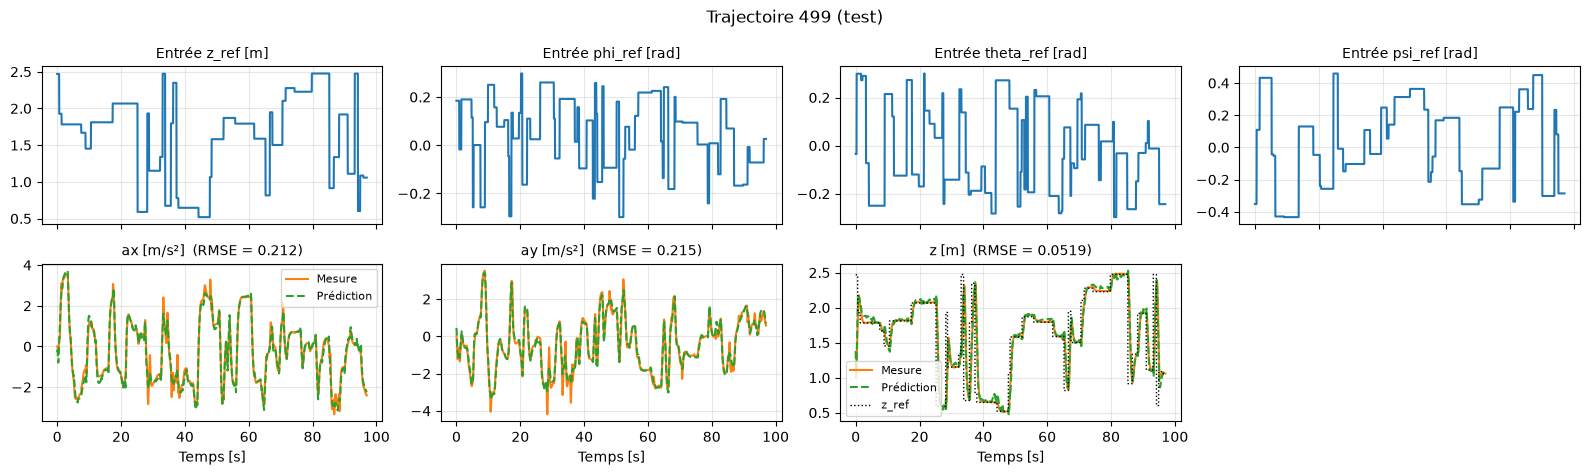

In [37]:
# Display results ----------------------------------------------------------------------------------------------------------------------------------
model_path = None                                                    # Modèle à afficher (None = le dernier entraîné)
if model_path is None:
    import glob
    model_path = max(glob.glob('model_rnn/lightning_logs/version_*/model.ckpt'), key=os.path.getmtime)
i_traj = -1                                                          # Trajectoire affichée (-1 = la dernière, dans le jeu de test)

# Chargement du modèle
model = model_nn.load_from_checkpoint(model_path, map_location=device)
model.eval()
print(f"Modèle {model_path} : {model.hparams.rnn_type} {model.hparams.hidden_size}, "
      f"{model.hparams.input_size} entrées -> {model.hparams.output_size} sorties {noms_y}")
if (model.hparams.input_size, model.hparams.output_size) != (tensor_u.shape[-1], tensor_y.shape[-1]):
    raise ValueError(f"Le modèle attend {model.hparams.input_size} entrées / {model.hparams.output_size} sorties, "
                     f"les données en ont {tensor_u.shape[-1]} / {tensor_y.shape[-1]}.")
sorties_mpc = ['ax', 'ay', 'z']                                      # ordre des sorties attendu par mpc.py et apply_EKF.py
if noms_y != sorties_mpc:
    print(f"ATTENTION : sorties {noms_y}, mpc.py attend {sorties_mpc} (dans cet ordre).")

# Normalisation : mêmes statistiques que dataModule.setup (par variable, sur les 70 % de trajectoires d'entraînement)
N = tensor_u.shape[0]
N_train, N_val = int(N * 0.7), int(N * 0.15)
u_mean = tensor_u[:N_train].mean(dim=(0, 1), keepdim=True)
u_std = tensor_u[:N_train].std(dim=(0, 1), keepdim=True).clamp_min(1e-8)
y_mean = tensor_y[:N_train].mean(dim=(0, 1), keepdim=True)
y_std = tensor_y[:N_train].std(dim=(0, 1), keepdim=True).clamp_min(1e-8)

# Statistiques à recopier dans MPC.__init__ (mpc.py) : elles servent aussi à l'EKF (u_mean, u_std, sr_mean, sr_std)
def tenseur(x):
    return "torch.tensor([" + ", ".join(f"{v:.6f}" for v in x.flatten().tolist()) + "])"
print(f"\nÀ recopier dans MPC.__init__ (mpc.py) :")
print(f"        self.u_m = {tenseur(u_mean)}   # {', '.join(noms_u)}")
print(f"        self.u_s = {tenseur(u_std)}")
print(f"        self.a_m = {tenseur(y_mean)}             # {', '.join(noms_y)}")
print(f"        self.a_s = {tenseur(y_std)}")

def predire(u):
    """u : (B, T, n_u) en unités physiques -> prédiction (B, T, n_y) en unités physiques (sur CPU)."""
    with torch.no_grad():
        u_n = ((u - u_mean) / u_std).to(device)                     # normalisation sur CPU, puis envoi sur le device
        return model(u_n).cpu() * y_std + y_mean

# Erreur par sortie sur tout le jeu de test (par paquets pour limiter la mémoire)
u_test_set = tensor_u[N_train + N_val:]
y_test_set = tensor_y[N_train + N_val:]
y_hat_test = torch.cat([predire(u_test_set[i:i + 256]) for i in range(0, len(u_test_set), 256)])
rmse = (y_hat_test - y_test_set).pow(2).mean(dim=(0, 1)).sqrt()     # (n_y,) en unités physiques
rmse_rel = rmse / y_std.flatten()                                   # 1 = pas mieux que prédire la moyenne
print(f"\nErreur sur le jeu de test ({len(u_test_set)} trajectoires) :")
print(f"{'sortie':>12} {'RMSE':>10} {'RMSE / écart-type':>18}")
for k, nom in enumerate(noms_y):
    print(f"{nom:>12} {rmse[k].item():>10.4g} {rmse_rel[k].item():>18.3f}")

# Graphes de comparaison sur une trajectoire : une case par entrée, puis une case par sortie
u_seq = tensor_u[i_traj]                                            # (T, n_u)
y_seq = tensor_y[i_traj]                                            # (T, n_y)
y_hat = predire(u_seq[None])[0]                                     # (T, n_y)
t = np.arange(u_seq.shape[0]) * Te
n_u, n_y = u_seq.shape[-1], y_seq.shape[-1]
unites = {'ax': 'm/s²', 'ay': 'm/s²', 'az': 'm/s²', 'x': 'm', 'y': 'm', 'z': 'm',
          'z_ref': 'm', 'phi_ref': 'rad', 'theta_ref': 'rad', 'psi_ref': 'rad'}

n_col = 4
lig_u, lig_y = math.ceil(n_u / n_col), math.ceil(n_y / n_col)
fig, axs = plt.subplots(lig_u + lig_y, n_col, figsize=(4 * n_col, 2.4 * (lig_u + lig_y)), sharex=True, squeeze=False)
num_traj = i_traj % N
fig.suptitle(f"Trajectoire {num_traj} ({'test' if num_traj >= N_train + N_val else 'entraînement/validation'})")

for k in range(n_u):
    ax = axs[k // n_col, k % n_col]
    ax.plot(t, u_seq[:, k], color='tab:blue')
    ax.set_title(f"Entrée {noms_u[k]} [{unites.get(noms_u[k], '-')}]", fontsize=10)

for k in range(n_y):
    ax = axs[lig_u + k // n_col, k % n_col]
    ax.plot(t, y_seq[:, k], color='tab:orange', label="Mesure")
    ax.plot(t, y_hat[:, k], color='tab:green', linestyle='--', label="Prédiction")
    if noms_y[k] == 'z' and 'z_ref' in noms_u:                      # z suit z_ref : on superpose la consigne
        ax.plot(t, u_seq[:, noms_u.index('z_ref')], color='k', linestyle=':', linewidth=1, label="z_ref")
        ax.legend(fontsize=8)
    r = (y_hat[:, k] - y_seq[:, k]).pow(2).mean().sqrt().item()
    ax.set_title(f"{noms_y[k]} [{unites.get(noms_y[k], '-')}]  (RMSE = {r:.3g})", fontsize=10)

axs[lig_u, 0].legend(fontsize=8)
for ax in axs.flat:
    ax.grid(True, alpha=0.3)
for k in range(n_y, lig_y * n_col):                                 # cases vides en fin de grille
    axs[lig_u + k // n_col, k % n_col].set_visible(False)
for ax in axs[-1]:
    ax.set_xlabel("Temps [s]")

plt.tight_layout()
plt.show()